# Extending the DCR model to blue objects (Nada 2026-10-31: 'go ahead')

The two-line DCR model clips c_rel at -1.5, and brick_DCR corrects only -2 < c_rel < 3, so 38% of Gaia white-dwarf
measurements are under-corrected and 11% are not corrected at all (`run/wd-dcr.ipynb`). Here: the raw DCR signal
(offset along the parallactic direction / tan z, before any correction) at the blue end, from the Gaia white dwarfs
plus a 10% sample of other Gaia stars (cache from wd-dcr), and the best blue clip colour c_min per band if the model
is kept as two lines and held flat beyond c_min, applied to every colour (no -2 cut).

g: best c_min -1.90; weighted rms of residual medians at c < -1: current 13.1 -> new 2.0 mas per tan z
r: best c_min -2.40; weighted rms of residual medians at c < -1: current 3.5 -> new 1.0 mas per tan z
i: best c_min -1.85; weighted rms of residual medians at c < -1: current 1.6 -> new 0.9 mas per tan z
z: best c_min -1.50; weighted rms of residual medians at c < -1: current 0.9 -> new 0.9 mas per tan z
fraction of WD epochs with c_rel below each best clip: {'g': 0.19138653298080555, 'r': 0.0029588230459439467, 'i': 0.22179512006196747, 'z': 0.47749000775954203}


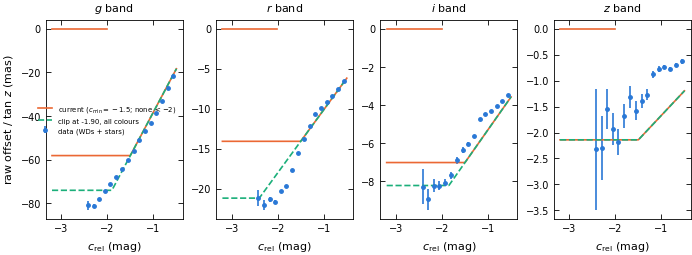

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import dcr_fit, dcr_geometry, plot_style as ps
from py_files.pm_analysis import COMBINED_DIR
ps.apply()
W = dict(np.load(os.path.join(COMBINED_DIR, 'wd_dcr_sample.npz')))
M = dcr_geometry.DCR_MODEL
E = np.r_[-3.5, np.arange(-3.0, -0.49, 0.125)]
def cells(sel):
    out = []
    for a, b in zip(E[:-1], E[1:]):
        q = sel & (W['c_rel'] >= a) & (W['c_rel'] < b)
        if q.sum() >= 300:
            y = W['par_raw'][q] / W['tanz'][q]
            out.append((np.median(W['c_rel'][q]), np.median(y), 1.2533 * 1.4826 * np.median(np.abs(y - np.median(y))) / np.sqrt(q.sum()), q.sum()))
    return np.array(out)

def model(band, c, c_min):
    m = dict(M); m['c_min'] = c_min
    return dcr_geometry.dcr_shift_mas(np.full(len(c), band), c, np.ones(len(c)), model=m)

res = {}
fig, axes = plt.subplots(1, 4, figsize=(ps.PAGE, 2.6), layout='constrained')
for ax, band in zip(axes, 'griz'):
    C = cells(W['band'] == band)
    c, y, e, n = C.T
    ax.errorbar(c, y, e, fmt='o', ms=2.5, color=ps.SERIES[0], label='data (WDs + stars)')
    cc = np.linspace(-3.2, -0.5, 200)
    ax.plot(cc, model(band, cc, -1.5), color=ps.SERIES[1], label='current ($c_{\\min}=-1.5$; none $<-2$)')
    ax.plot(cc[cc < -2], np.zeros((cc < -2).sum()), color=ps.SERIES[1])
    best = None
    blue = c < -1.0
    for cm in np.arange(-1.5, -3.01, -0.05):
        r = y[blue] - model(band, c[blue], cm)
        chi = np.sum((r / e[blue])**2)
        if best is None or chi < best[1]:
            best = (cm, chi, np.sqrt(np.average(r**2, weights=n[blue])))
    cur = y[blue] - np.where(c[blue] < -2, 0, model(band, c[blue], -1.5))
    res[band] = dict(c_min=round(float(best[0]), 2), rms_new=float(best[2]), rms_current=float(np.sqrt(np.average(cur**2, weights=n[blue]))))
    ax.plot(cc, model(band, cc, best[0]), color=ps.SERIES[2], ls='--', label=f'clip at {best[0]:.2f}, all colours')
    ax.set_title(f'${band}$ band'); ax.set_xlabel(r'$c_{\rm rel}$ (mag)')
axes[0].set_ylabel('raw offset / tan $z$ (mas)'); axes[0].legend(fontsize=5)
plt.savefig('plots/dcr_blue_extension.pdf')
for b, r in res.items():
    print(f"{b}: best c_min {r['c_min']:+.2f}; weighted rms of residual medians at c < -1: current {r['rms_current']:.1f} -> new {r['rms_new']:.1f} mas per tan z")
print('fraction of WD epochs with c_rel below each best clip:', {b: float(np.mean(W['c_rel'][W['wd'] & (W['band'] == b)] < r['c_min'])) for b, r in res.items()})